In [ ]:
# House Price Prediction using Machine Learning

Steps:
1. Data Loading
2. Exploratory Data Analysis (EDA)
3. Observations
4. Data Preprocessing
5. Model Building
6. Model Comparison
7. Conclusion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import json

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score, mean_absolute_error

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [2]:
data = pd.read_csv("cleaned_mumbai_housing.csv")
data.head()

,bhk,type,locality,area,price,region,status,age
0,3,Apartment,Lak And Hanware The Residency Tower,685,250.00,Andheri West,Ready to move,New
1,2,Apartment,Radheya Sai Enclave Building No 2,640,52.51,Naigaon East,Under Construction,New
2,2,Apartment,Romell Serene,610,173.00,Borivali West,Under Construction,New
3,2,Apartment,Soundlines Codename Urban Rainforest,876,59.98,Panvel,Under Construction,New
4,2,Apartment,Origin Oriana,659,94.11,Mira Road East,Under Construction,New


In [7]:
print("Shape:", data.shape)
data.info()

Shape: (76038, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76038 entries, 0 to 76037
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   bhk       76038 non-null  int64  
 1   type      76038 non-null  object 
 2   locality  76038 non-null  object 
 3   area      76038 non-null  int64  
 4   price     76038 non-null  float64
 5   region    76038 non-null  object 
 6   status    76038 non-null  object 
 7   age       76038 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 4.6+ MB


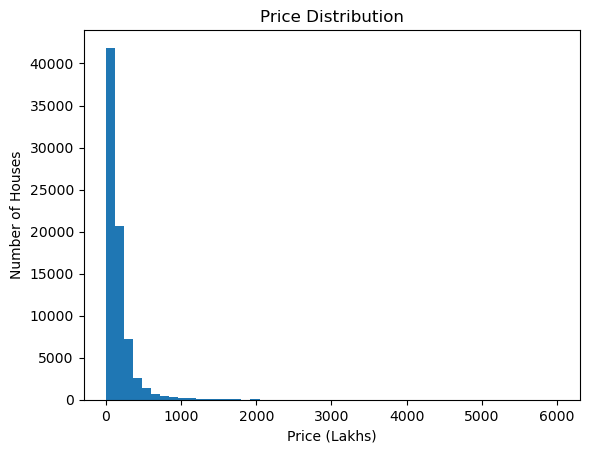

In [8]:
plt.figure()
plt.hist(data['price'], bins=50)
plt.title("Price Distribution")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Houses")
plt.show()

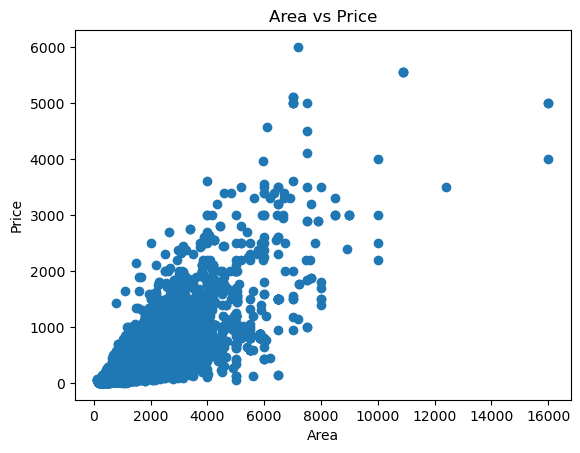

In [5]:
plt.figure()
plt.scatter(data['area'], data['price'])
plt.title("Area vs Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

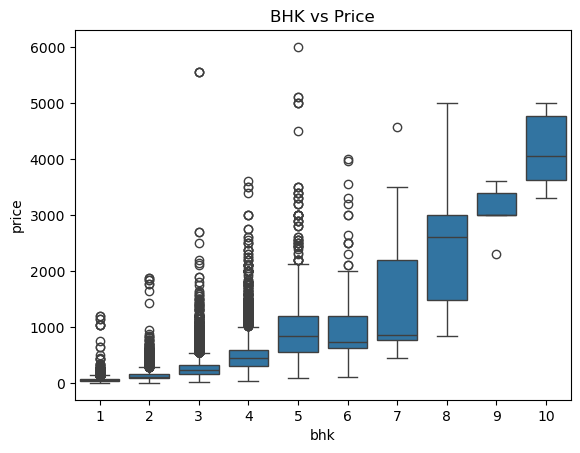

In [6]:
plt.figure()
sns.boxplot(x=data['bhk'], y=data['price'])
plt.title("BHK vs Price")
plt.show()

In [ ]:
## Observations

- Price distribution is highly skewed
- Presence of extreme outliers (very low and very high prices)
- Area has a positive relationship with price
- Higher BHK generally leads to higher price

These observations indicate the need for data cleaning before training models.

In [3]:
df = data[(data['price'] > 50) & (data['price'] < 1000)]

print("Original shape:", data.shape)
print("After cleaning:", df.shape)

Original shape: (76038, 8)
After cleaning: (63085, 8)


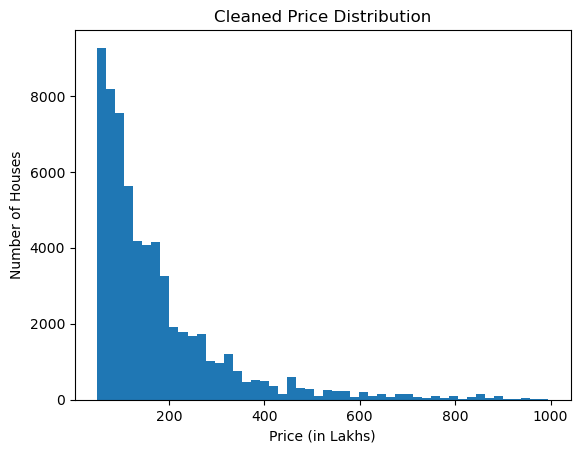

In [10]:
plt.figure()

plt.hist(df['price'], bins=50)

plt.title("Cleaned Price Distribution")
plt.xlabel("Price (in Lakhs)")   # X-axis label
plt.ylabel("Number of Houses")   # Y-axis label

plt.show()

In [4]:
X = df[['area', 'bhk', 'region', 'type', 'status', 'age']]
y = df['price']

In [5]:
label_encoders = {}
categorical_cols = ['region', 'type', 'status', 'age']

X = X.copy()

for col in categorical_cols:
    le = LabelEncoder()
    X.loc[:, col] = le.fit_transform(X[col])
    label_encoders[col] = le

In [6]:
label_encoders['region'].classes_

array(['Agripada', 'Airoli', 'Ambernath East', 'Ambernath West',
       'Ambivali', 'Andheri East', 'Andheri West', 'Anjurdive',
       'Antop Hill', 'Ashok nagar', 'Badlapur East', 'Badlapur West',
       'Bandra East', 'Bandra Kurla Complex', 'Bandra West', 'Belapur',
       'Bhandup East', 'Bhandup West', 'Bhayandar East', 'Bhayandar West',
       'Bhiwandi', 'Boisar', 'Borivali', 'Borivali East', 'Borivali West',
       'Byculla', 'Chandivali', 'Chembur', 'Chembur East', 'Churchgate',
       'Colaba', 'Cuffe Parade', 'Dadar East', 'Dadar West', 'Dahisar',
       'Dahisar East', 'Dahisar West', 'Deonar', 'Dharavi', 'Diva',
       'Dombivali', 'Dombivali East', 'Dronagiri', 'Fort', 'GTB Nagar',
       'Ghansoli', 'Ghatkopar East', 'Ghatkopar West', 'Ghodbunder Road',
       'Girgaon', 'Goregaon', 'Goregaon East', 'Goregaon West', 'Govandi',
       'Greater Khanda', 'Hindu Colony', 'Hiranandani Estates',
       'Jogeshwari East', 'Jogeshwari West', 'Juhu', 'Juhu Scheme',
       'Juina

In [7]:
X.head()

,area,bhk,region,type,status,age
0,685,3,6,0,0,0
1,640,2,106,0,1,0
2,610,2,24,0,1,0
3,876,2,118,0,1,0
4,659,2,100,0,1,0


In [17]:
data['region'].head()

0      Andheri West
1      Naigaon East
2     Borivali West
3            Panvel
4    Mira Road East
Name: region, dtype: object

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [9]:
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

print("Linear Regression R2:", r2_score(y_test, lr_pred))
print("Linear Regression MAE:", mean_absolute_error(y_test, lr_pred))

Linear Regression R2: 0.5620703053144499
Linear Regression MAE: 62.13370605066589


In [10]:
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print("Decision Tree R2:", r2_score(y_test, dt_pred))
print("Decision Tree MAE:", mean_absolute_error(y_test, dt_pred))

Decision Tree R2: 0.8309618389609451
Decision Tree MAE: 25.081153284236976


In [11]:
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest R2:", r2_score(y_test, rf_pred))
print("Random Forest MAE:", mean_absolute_error(y_test, rf_pred))

Random Forest R2: 0.8890164665030497
Random Forest MAE: 23.90049810107687


In [14]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "R2 Score": [
        r2_score(y_test, lr_pred),
        r2_score(y_test, dt_pred),
        r2_score(y_test, rf_pred)
    ],
    "MAE": [
        mean_absolute_error(y_test, lr_pred),
        mean_absolute_error(y_test, dt_pred),
        mean_absolute_error(y_test, rf_pred)
    ],
    "MSE": [
        mean_squared_error(y_test, lr_pred),
        mean_squared_error(y_test, dt_pred),
        mean_squared_error(y_test, rf_pred)
    ]
})

results

,Model,R2 Score,MAE,MSE
0,Linear Regression,0.562070,62.133706,9092.281165
1,Decision Tree,0.830962,25.081153,3509.564449
2,Random Forest,0.889016,23.900498,2304.236281


In [ ]:
## Conclusion

- Linear Regression → Lower accuracy
- Decision Tree → Moderate accuracy
- Random Forest → Highest accuracy

Random Forest performs best because it combines multiple trees and reduces overfitting.

Therefore, Random Forest is selected as the final model for deployment.

In [ ]:
pickle.dump(rf, open("house_price_model_.pkl", "wb"))
pickle.dump(label_encoders, open("encoders.pkl", "wb"))

with open("features.json", "w") as f:
    json.dump(list(X.columns), f)

options = {
    "regions": list(df["region"].unique()),
    "types": list(df["type"].unique()),
    "status": list(df["status"].unique()),
    "age": list(df["age"].unique())
}

with open("options.json", "w") as f:
    json.dump(options, f)

print("✅ Model saved successfully!")